# Softmax Regression From Scratch Workflow

This notebook implements multiclass logistic regression directly with NumPy to make the training loop, gradients, regularization, and early stopping explicit.

## Workflow Overview

**Objective:** train a multiclass classifier without relying on Scikit-Learn's estimator implementation.

**Dataset:** Iris classification data.

**Primary metric:** accuracy on train, validation, and test splits; validation cross-entropy is used for early stopping.

**Validation strategy:** stratified train/validation/test split; training updates use only the training set; validation selects the best epoch; test evaluation is saved for the end.

**Production mindset:** this is not meant as a production model implementation. It is a transparent reference implementation for understanding what library models do internally.

## Stage 0 - Environment Setup

Import numerical, plotting, and dataset utilities used by the from-scratch implementation.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## Stage 1 - Softmax Regression Training Loop

Prepare data, implement one-hot encoding, softmax probabilities, cross-entropy loss, L2 regularization, analytical gradients, prediction, and early stopping.

Implement softmax regression using NumPy only for the model training code.

We use the Iris dataset. The model predicts one of three classes:

- setosa
- versicolor
- virginica

The implementation below does the following:

1. loads Iris data
2. creates train/validation/test splits
3. standardizes features using training-set statistics
4. adds a bias column
5. implements softmax, cross-entropy loss, gradients, and prediction
6. trains with batch gradient descent
7. uses early stopping based on validation loss
8. evaluates on the test set

In [5]:
iris = load_iris()
X_iris = iris.data.astype(float)
y_iris = iris.target.astype(int)
class_names = iris.target_names

X_iris.shape, y_iris.shape, class_names

((150, 4), (150,), array(['setosa', 'versicolor', 'virginica'], dtype='<U10'))

In [6]:
def stratified_train_valid_test_split(X, y, train_ratio=0.6, valid_ratio=0.2, random_state=42):
    rng = np.random.default_rng(random_state)
    train_indices = []
    valid_indices = []
    test_indices = []

    for class_id in np.unique(y):
        class_indices = np.flatnonzero(y == class_id)
        rng.shuffle(class_indices)
        n_train = int(len(class_indices) * train_ratio)
        n_valid = int(len(class_indices) * valid_ratio)

        train_indices.extend(class_indices[:n_train])
        valid_indices.extend(class_indices[n_train:n_train + n_valid])
        test_indices.extend(class_indices[n_train + n_valid:])

    train_indices = rng.permutation(train_indices)
    valid_indices = rng.permutation(valid_indices)
    test_indices = rng.permutation(test_indices)

    return (
        X[train_indices], y[train_indices],
        X[valid_indices], y[valid_indices],
        X[test_indices], y[test_indices],
    )


X_train, y_train, X_valid, y_valid, X_test, y_test = stratified_train_valid_test_split(
    X_iris,
    y_iris,
    random_state=RANDOM_STATE,
)

X_train.shape, X_valid.shape, X_test.shape

((90, 4), (30, 4), (30, 4))

In [7]:
# Standardize with training-set statistics only.
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)
train_std[train_std == 0] = 1.0

X_train_scaled = (X_train - train_mean) / train_std
X_valid_scaled = (X_valid - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std


def add_bias(X):
    return np.c_[np.ones(len(X)), X]


X_train_b = add_bias(X_train_scaled)
X_valid_b = add_bias(X_valid_scaled)
X_test_b = add_bias(X_test_scaled)

X_train_b[:3]

array([[ 1.        ,  0.945612  , -0.23176973,  0.66781493,  0.65395281],
       [ 1.        ,  0.46749357, -0.47431945,  1.00674356,  0.78832668],
       [ 1.        ,  0.46749357, -0.71686916,  0.72430303,  0.38520508]])

In [8]:
def to_one_hot(y, n_classes):
    one_hot = np.zeros((len(y), n_classes))
    one_hot[np.arange(len(y)), y] = 1
    return one_hot


def softmax(logits):
    shifted_logits = logits - logits.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted_logits)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def cross_entropy_loss(X_b, y, theta, alpha=0.0):
    m = len(X_b)
    y_proba = softmax(X_b @ theta)
    correct_class_probas = y_proba[np.arange(m), y]
    loss = -np.mean(np.log(correct_class_probas + 1e-15))
    l2_penalty = alpha * np.sum(theta[1:] ** 2) / (2 * m)
    return loss + l2_penalty


def softmax_gradient(X_b, y, theta, alpha=0.0):
    m = len(X_b)
    n_classes = theta.shape[1]
    y_one_hot = to_one_hot(y, n_classes)
    y_proba = softmax(X_b @ theta)
    gradients = X_b.T @ (y_proba - y_one_hot) / m
    gradients[1:] += alpha * theta[1:] / m
    return gradients


def predict_softmax(X_b, theta):
    return softmax(X_b @ theta).argmax(axis=1)

In [9]:
n_inputs = X_train_b.shape[1]
n_classes = len(np.unique(y_iris))

eta = 0.5
alpha = 0.01
n_epochs = 50_000
patience = 500

rng = np.random.default_rng(RANDOM_STATE)
theta = rng.normal(scale=0.01, size=(n_inputs, n_classes))

best_theta = theta.copy()
best_valid_loss = np.inf
best_epoch = 0
epochs_without_improvement = 0
history = []

for epoch in range(n_epochs):
    gradients = softmax_gradient(X_train_b, y_train, theta, alpha=alpha)
    theta -= eta * gradients

    train_loss = cross_entropy_loss(X_train_b, y_train, theta, alpha=alpha)
    valid_loss = cross_entropy_loss(X_valid_b, y_valid, theta, alpha=alpha)
    history.append((epoch, train_loss, valid_loss))

    if valid_loss < best_valid_loss - 1e-7:
        best_valid_loss = valid_loss
        best_theta = theta.copy()
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        break

theta = best_theta

pd.Series({
    "best_epoch": best_epoch,
    "best_validation_loss": best_valid_loss,
    "epochs_run": len(history),
})

best_epoch              1293.000000
best_validation_loss       0.079942
epochs_run              1794.000000
dtype: float64

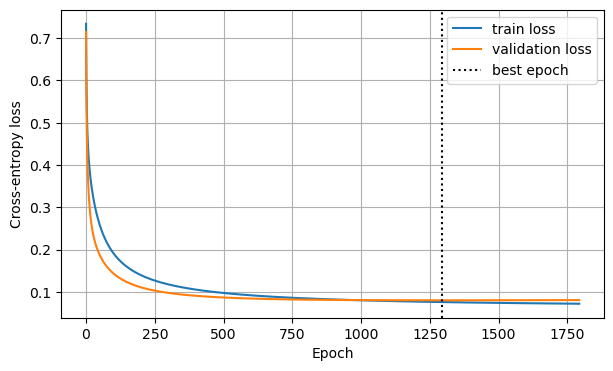

In [10]:
history_df = pd.DataFrame(history, columns=["epoch", "train_loss", "valid_loss"])

plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train loss")
plt.plot(history_df["epoch"], history_df["valid_loss"], label="validation loss")
plt.axvline(best_epoch, color="black", linestyle=":", label="best epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.grid(True)
plt.legend()
plt.show()

In [11]:
train_pred = predict_softmax(X_train_b, theta)
valid_pred = predict_softmax(X_valid_b, theta)
test_pred = predict_softmax(X_test_b, theta)

pd.Series({
    "train_accuracy": (train_pred == y_train).mean(),
    "validation_accuracy": (valid_pred == y_valid).mean(),
    "test_accuracy": (test_pred == y_test).mean(),
})

train_accuracy         0.977778
validation_accuracy    1.000000
test_accuracy          1.000000
dtype: float64

In [12]:
pd.DataFrame({
    "true_class": class_names[y_test],
    "predicted_class": class_names[test_pred],
    "correct": test_pred == y_test,
}).head(15)

,true_class,predicted_class,correct
0,versicolor,versicolor,True
1,virginica,virginica,True
2,versicolor,versicolor,True
3,setosa,setosa,True
4,virginica,virginica,True
5,virginica,virginica,True
6,setosa,setosa,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,virginica,True


## Workflow Summary and Next Steps

Summarize the implementation choices and possible extensions such as mini-batch training, learning-rate schedules, and comparison with Scikit-Learn.

The training-models implementation is complete.

The key ideas are:

- use gradient descent for very high-dimensional linear regression
- scale features before gradient descent and regularized linear models
- logistic regression has a convex cost function
- validation curves help diagnose overfitting or divergence
- regularization controls the bias/variance tradeoff
- softmax regression can be trained directly with NumPy using cross-entropy gradients and early stopping